# Scania APS — EDA and Logistic Regression Baseline


## 1. Purpose

This notebook:

- performs additional exploratory analysis focused on modelling
- trains a **DummyClassifier** reference (most frequent class)
- trains a **Logistic Regression** baseline with agreed preprocessing
- uses **only** the official training CSV (`aps_failure_training_set.csv`)
- keeps the official Scania **test** set reserved for final evaluation (not loaded here)

Results below are **internal validation** on a held-out 20% slice of the training data, not official test performance.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.load_data import TARGET_COLUMN, load_training_data
from src.data.preprocess import (
    class_distribution,
    encode_binary_target,
    find_constant_columns,
    missingness_summary,
    split_features_target,
)
from src.evaluation.metrics import evaluate_binary_classifier
from src.models.baseline import (
    CONSTANT_FEATURE_TO_DROP,
    build_dummy_reference_classifier,
    build_logistic_regression_pipeline,
)

RANDOM_STATE = 42
TEST_SIZE = 0.2


## 2. Load training data


In [2]:
train = load_training_data()
print(f"Training shape: {train.shape}")
assert train.shape[1] == 171
assert TARGET_COLUMN in train.columns
train.head()


Training shape: (60000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


## 3. Target preparation


In [3]:
X, y_raw = split_features_target(train)
y = encode_binary_target(y_raw)

target_summary = class_distribution(train)
target_summary


,count,percent
class,,
neg,59000,98.333333
pos,1000,1.666667


In [4]:
print("Encoded target value counts:")
print(y.value_counts().sort_index())
print((y.value_counts(normalize=True) * 100).sort_index().round(2))


Encoded target value counts:
class
0    59000
1     1000
Name: count, dtype: int64
class
0    98.33
1     1.67
Name: proportion, dtype: float64


## 4. Additional EDA

Concise modelling-oriented checks (full data-quality review: `notebooks/01_data_quality.ipynb`). Features are anonymised — no physical interpretation.


       count    percent
class                  
neg    59000  98.333333
pos     1000   1.666667


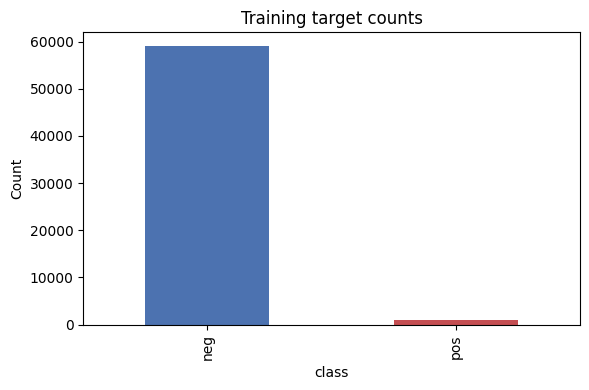

In [5]:
print(target_summary)
fig, ax = plt.subplots(figsize=(6, 4))
target_summary["count"].plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Training target counts")
ax.set_xlabel("class")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


In [6]:
feature_missing = missingness_summary(X)
total_missing_pct = X.isna().sum().sum() / X.size * 100
print(f"Overall missing share among feature cells: {total_missing_pct:.2f}%")
feature_missing.head(10)


Overall missing share among feature cells: 8.33%


,missing_count,missing_percent
br_000,49264,82.106667
bq_000,48722,81.203333
bp_000,47740,79.566667
bo_000,46333,77.221667
ab_000,46329,77.215000
cr_000,46329,77.215000
bn_000,44009,73.348333
bm_000,39549,65.915000
bl_000,27277,45.461667
bk_000,23034,38.390000


count    60000.000000
mean        14.166917
std         16.095888
min          0.000000
25%          8.000000
50%          8.000000
75%         16.000000
max        168.000000
dtype: float64


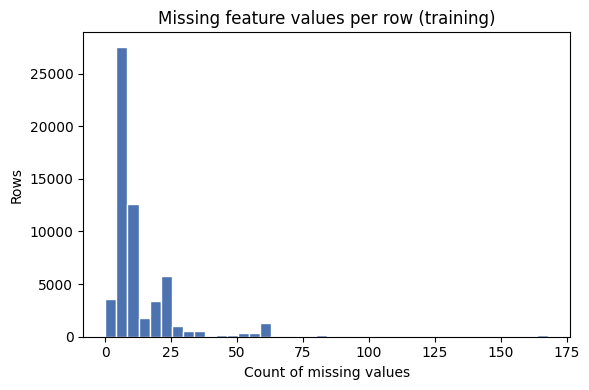

In [7]:
row_missing = X.isna().sum(axis=1)
print(row_missing.describe())
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(row_missing, bins=40, color="#4C72B0", edgecolor="white")
ax.set_title("Missing feature values per row (training)")
ax.set_xlabel("Count of missing values")
ax.set_ylabel("Rows")
plt.tight_layout()
plt.show()


In [8]:
row_missing_by_class = pd.DataFrame(
    {"missing_per_row": row_missing, "class": y_raw}
)
row_missing_by_class.groupby("class")["missing_per_row"].describe()


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
neg,59000.0,13.912915,15.822130,0.0,8.00,8.0,14.0,168.0
pos,1000.0,29.153000,23.382822,0.0,9.75,20.5,53.0,168.0


In [9]:
numeric_summary = X.describe().T[["mean", "std", "min", "max"]]
numeric_summary.head(10)


,mean,std,min,max
aa_000,5.933650e+04,1.454301e+05,0.0,2.746564e+06
ab_000,7.131885e-01,3.478962e+00,0.0,2.040000e+02
ac_000,3.560143e+08,7.948749e+08,0.0,2.130707e+09
ad_000,1.906206e+05,4.040441e+07,0.0,8.584298e+09
ae_000,6.819130e+00,1.615434e+02,0.0,2.105000e+04
af_000,1.100682e+01,2.097926e+02,0.0,2.007000e+04
ag_000,2.216364e+02,2.047846e+04,0.0,3.376892e+06
ag_001,9.757223e+02,3.420053e+04,0.0,4.109372e+06
ag_002,8.606015e+03,1.503220e+05,0.0,1.055286e+07
ag_003,8.859128e+04,7.617312e+05,0.0,6.340207e+07


## 5. Train/validation split

80% development / 20% validation, stratified on the encoded target (`random_state=42`).

**Official test set:** not loaded and not used in this notebook.


In [10]:
constant_cols = find_constant_columns(train)
print(f"Constant feature columns (training): {constant_cols}")
if CONSTANT_FEATURE_TO_DROP not in constant_cols:
    raise ValueError(
        f"Expected {CONSTANT_FEATURE_TO_DROP} to remain constant before dropping."
    )

X_dev, X_val, y_dev, y_val = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Development rows: {len(X_dev):,}")
print(f"Validation rows: {len(X_val):,}")
print("Development class counts (0=neg, 1=pos):")
print(y_dev.value_counts().sort_index())
print("Validation class counts (0=neg, 1=pos):")
print(y_val.value_counts().sort_index())


Constant feature columns (training): ['cd_000']
Development rows: 48,000
Validation rows: 12,000
Development class counts (0=neg, 1=pos):
class
0    47200
1      800
Name: count, dtype: int64
Validation class counts (0=neg, 1=pos):
class
0    11800
1      200
Name: count, dtype: int64


## 6. Dummy reference

`DummyClassifier(strategy="most_frequent")` illustrates why **accuracy** can look high while the model is useless for detecting failures.


In [11]:
dummy = build_dummy_reference_classifier()
dummy.fit(X_dev, y_dev)
dummy_pred = dummy.predict(X_val)
dummy_metrics = evaluate_binary_classifier(y_val, dummy_pred)
dummy_metrics


{'accuracy': 0.9833333333333333,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'tn': 11800,
 'fp': 0,
 'fn': 200,
 'tp': 0,
 'business_cost': 100000}

In [12]:
cm_dummy = confusion_matrix(y_val, dummy_pred, labels=[0, 1])
print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
print(cm_dummy)
print(f"Scania business cost: {dummy_metrics['business_cost']:,}")


Confusion matrix [ [TN, FP], [FN, TP] ]:
[[11800     0]
 [  200     0]]
Scania business cost: 100,000


## 7. Logistic Regression baseline

Pipeline (fit on development data only):

- drop constant `cd_000`
- median imputation + missing indicators
- `StandardScaler`
- `LogisticRegression(class_weight="balanced", max_iter=2000)`

High-missing and zero-heavy features are **kept** for this baseline (dropping high-missing columns can be tested later). Threshold = 0.5.


In [13]:
lr_pipeline = build_logistic_regression_pipeline(random_state=RANDOM_STATE)
lr_pipeline.fit(X_dev, y_dev)
lr_pred = lr_pipeline.predict(X_val)
lr_scores = lr_pipeline.predict_proba(X_val)[:, 1]
lr_metrics = evaluate_binary_classifier(y_val, lr_pred, y_score=lr_scores)
lr_metrics


{'accuracy': 0.9683333333333334,
 'precision': 0.3357664233576642,
 'recall': 0.92,
 'f1': 0.4919786096256685,
 'tn': 11436,
 'fp': 364,
 'fn': 16,
 'tp': 184,
 'business_cost': 11640,
 'pr_auc': 0.721402191932798}

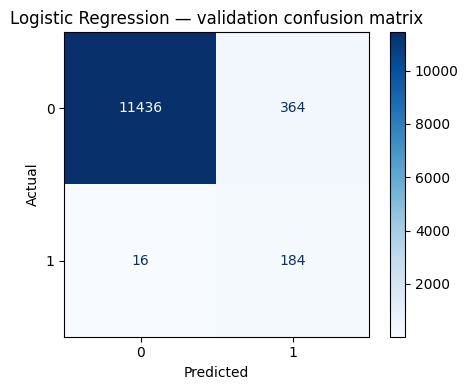

False positives: 364
False negatives: 16
Scania business cost: 11,640


In [14]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_val, lr_pred, display_labels=[0, 1], ax=ax, cmap="Blues"
)
ax.set_title("Logistic Regression — validation confusion matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

print(f"False positives: {lr_metrics['fp']}")
print(f"False negatives: {lr_metrics['fn']}")
print(f"Scania business cost: {lr_metrics['business_cost']:,}")


## 8. Compare reference vs Logistic Regression


In [15]:
comparison = pd.DataFrame(
    {
        "Dummy reference": dummy_metrics,
        "Logistic Regression": lr_metrics,
    }
).T[
    [
        "accuracy",
        "precision",
        "recall",
        "f1",
        "fp",
        "fn",
        "business_cost",
    ]
]
comparison


,accuracy,precision,recall,f1,fp,fn,business_cost
Dummy reference,0.983333,0.000000,0.00,0.000000,0.0,200.0,100000.0
Logistic Regression,0.968333,0.335766,0.92,0.491979,364.0,16.0,11640.0


## 9. Conclusions

**Internal validation only** — not official test-set results.

- The dummy reference achieves very high **accuracy** by always predicting the majority class (`neg`), but **zero recall** for failures and a very large **business cost** (missed failures dominate).
- Logistic Regression improves **recall**, **F1**, and especially **Scania business cost** versus the dummy, at the cost of more false positives (extra inspections).
- **Class imbalance** means accuracy is a poor primary metric; cost and recall matter for rare failures.
- Preprocessing: drop `cd_000`, median imputation with indicators, scaling, balanced logistic regression. High-missing columns were retained.
- **Limitations:** anonymised features, simple linear model, fixed 0.5 threshold, single stratified split.
- **Next step:** compare **Random Forest** using the same evaluation principles before any official test-set evaluation.
